# Chapter 96: Keynesian and Post-Keynesian Demand, Money, and Instability

This notebook reruns four worked examples from the chapter: a general wage cut that leaves profits unchanged, the spending flows that add up to aggregate profit, output set by expected demand below capacity, and full-cost pricing under a demand shock. Every number is one of the chapter's hypothetical values, not data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def kaleckian_output(omega, cw, cp, autonomous, capacity):
    """Demand-led output Y = A / (1 - cw omega - cp (1 - omega)), profits (1 - omega) Y.

    paradox-of-costs (chapter 96): capacity 125, workers spend all wages (cw = 1), profit recipients
    half (cp = 0.5). omega 0.60, A 20 gives Y = 100, profits 40, u = 0.80, profit rate 0.32;
    omega 0.50 gives Y = 80, profits 40, u = 0.64; A = 16 gives 64 and 32; A = 30 gives 120 and 60.
    """
    c = cw * omega + cp * (1.0 - omega)
    Y = autonomous / (1.0 - c)
    profits = (1.0 - omega) * Y
    return {"Y": Y, "profits": profits, "wages": omega * Y, "propensity": c, "u": Y / capacity,
            "profit_rate": profits / capacity, "multiplier": 1.0 / (1.0 - c)}


def kalecki_profits(Cc, I, deficit, NX, Sw):
    """Kalecki profit equation P = C_c + I + (G - T) + (X - M) - S_w.

    kalecki-profit-equation (chapter 96): 40 + 120 + 30 - 10 - 20 = 160; deficit 10 gives 140;
    investment 135 then gives 155; worker saving 15 then gives 160.
    """
    return Cc + I + deficit + NX - Sw


def keynesian_cross(a, c, I, G=0.0, T=0.0):
    """Fixed-price demand equilibrium Y = (a - cT + I + G) / (1 - c), with C = a + c(Y - T).

    paradox-of-thrift (chapter 53): a = 20, c = 0.8, I = 80 give Y = 100 / 0.2 = 500, C = 420, S = 80;
    a = 10 gives Y = 450, C = 370, S = 80. balanced-budget-multiplier: dG = dT = 40 at c = 0.75 raises
    Y by 40. Returns Y, C, S (private saving Y - T - C), multiplier 1 / (1 - c).
    """
    Y = (a - c * T + I + G) / (1.0 - c)
    C = a + c * (Y - T)
    return {"Y": Y, "C": C, "S": Y - T - C, "multiplier": 1.0 / (1.0 - c)}


def full_cost_price(v, K, Q, m):
    """Full-cost price P = (1 + m)(v + K / Q).

    administered-full-cost-pricing (chapter 96): v = 60, K = 2,000,000, Q = 100,000, m = 0.25 give
    unit cost 80 and price 100; v = 68 gives 110; overhead over 70,000 orders gives 120.71.
    Implemented by Part 10 (chapter 96 is its first user).
    """
    unit = v + K / Q
    return {"unit_cost": unit, "overhead": K / Q, "price": (1.0 + m) * unit, "markup": m * unit}


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(kaleckian_output=kaleckian_output, kalecki_profits=kalecki_profits, keynesian_cross=keynesian_cross)


industrial = SimpleNamespace(full_cost_price=full_cost_price)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'paradox-of-costs': {'capacity': 125,
                      'omega': 0.6,
                      'cw': 1.0,
                      'cp': 0.5,
                      'A': 20,
                      'Y': 100,
                      'profits': 40,
                      'u': 0.8,
                      'profit_rate': 0.32,
                      'omega_cut': 0.5,
                      'Y_cut': 80,
                      'profits_cut': 40,
                      'u_cut': 0.64,
                      'A_low': 16,
                      'Y_low': 64,
                      'profits_low': 32,
                      'profit_rate_low': 0.256,
                      'A_high': 30,
                      'Y_high': 120,
                      'profits_high': 60},
 'kalecki-profit-equation': {'Cc': 40,
                             'I': 120,
                             'deficit': 30,
                             'NX': -10,
                             'Sw': 20,
                             'P': 160,
                             'deficit_low': 10,
                             'P_low_def': 140,
                             'I_high': 135,
                             'P_high_I': 155,
                             'Sw_low': 15,
                             'P_back': 160},
 'principle-of-effective-demand': {'a': 20,
                                   'mpc': 0.75,
                                   'I': 10,
                                   'capacity': 160,
                                   'Y': 120,
                                   'idle': 40,
                                   'G': 8,
                                   'Y_G': 152,
                                   'G_full': 10,
                                   'Y_full': 160},
 'administered-full-cost-pricing': {'K': 2000000,
                                    'Q': 100000,
                                    'v': 60,
                                    'm': 0.25,
                                    'unit_cost': 80,
                                    'price': 100,
                                    'orders': 70000,
                                    'actual_cost': 88.57,
                                    'margin': 11.43,
                                    'v_high': 68,
                                    'unit_cost_high': 88,
                                    'price_high': 110,
                                    'price_current': 120.71},
 'constructed': {'paradox-of-costs': {'omega': [0.7]},
                 'principle-of-effective-demand': {'mpc': [0.7]}}}


LABEL = "Hypothetical teaching numbers, not data."


def costs_picture(omega=0.60, auto=20):
    b = BV["paradox-of-costs"]
    cap = b["capacity"]
    r = macro.kaleckian_output(omega, b["cw"], b["cp"], auto, cap)
    Y, P, c = r["Y"], r["profits"], r["propensity"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    top = max(220, Y * 1.12)
    ys = np.linspace(0, top, 50)
    ax1.plot(ys, ys, color=PALETTE["grey"], linewidth=1.6)
    ax1.plot(ys, auto + c * ys, color=PALETTE["navy"], linewidth=2.2)
    ax1.text(0.03, 0.96, f"E = {num(c)}Y + {auto}", transform=ax1.transAxes, ha="left", va="top", fontsize=10.5,
             color=PALETTE["navy"])
    ax1.text(0.97, 0.04, "grey: 45 degree line", transform=ax1.transAxes, ha="right", va="bottom", fontsize=10.5,
             color=PALETTE["grey"])
    vline(ax1, cap, f"capacity {cap}", col="terracotta", y_frac=0.85, ha="left")
    mark(ax1, Y, Y, f"Y = {num(Y)}", col="teal", dx=-8, dy=8, ha="right", va="bottom")
    ax1.set_xlim(0, top)
    ax1.set_ylim(0, top)
    ax1.set_xlabel("Output Y")
    ax1.set_ylabel("Planned expenditure E")
    bar_compare(ax2, ["Output Y", "Profits"], [Y, P], colors=["teal", "gold"],
                value_labels=[num(Y), num(P)], ylabel="Units", xlabel="Outcome")
    hline(ax2, cap, col="terracotta")
    ax2.annotate(f"capacity {cap}", (0.98, cap), xycoords=("axes fraction", "data"), xytext=(0, 4),
                 textcoords="offset points", ha="right", va="bottom", fontsize=10.5, color=PALETTE["terracotta"])
    ax2.set_ylim(0, 230)
    over = Y > cap + 1e-9
    if over:
        cap_text = (f"Demand of {num(Y)} exceeds capacity of {cap}, so this fixed-price solution cannot be produced; "
                    f"prices, imports or rationing would have to adjust.")
        util = "above capacity"
    else:
        cap_text = f"Utilization is {num(Y)} / {cap} = {num(r['u'], 3)} and the profit rate on capacity is {num(P)} / {cap} = {num(r['profit_rate'], 3)}."
        util = num(r["u"], 3)
    metrics = {"Spending propensity": num(c), "Output Y": num(Y), "Profits": num(P), "Utilization u": util,
               "Profit rate on capacity": "not feasible" if over else num(r["profit_rate"], 3)}
    steps = [f"Propensity = 1 x {num(omega)} + 0.5 x {num(1 - omega)} = {num(c)}",
             f"Y = {auto} / (1 - {num(c)}) = {auto} / {num(1 - c)} = {num(Y)}",
             f"Profits = {num(1 - omega)} x {num(Y)} = {num(P)}",
             f"Profit rate on capacity = {num(P)} / {cap} = {num(r['profit_rate'], 3)}"]
    if over:
        steps[-1] = f"Capacity check: {num(Y)} > {cap}, so this output cannot be produced"
    interp = (f"{LABEL} With wage share {num(omega)}, every unit of output brings {num(c)} of consumption, so "
              f"Y = {auto} / {num(1 - c)} = {num(Y)} and profits are {num(1 - omega)} x {num(Y)} = {num(P)}. "
              f"{cap_text} In this model profits equal twice autonomous demand whatever the wage share: a wage cut "
              f"raises the profit share but shrinks output.")
    alt = (f"Left: a 45 degree diagram with expenditure line slope {num(c)} meeting the 45 degree line at Y = "
           f"{num(Y)}, capacity at {cap}. Right: bars of output {num(Y)} and profits {num(P)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def profits_picture(deficit=30, inv=120, sw=20):
    I, Sw = inv, sw
    b = BV["kalecki-profit-equation"]
    Cc, NX = b["Cc"], b["NX"]
    P = macro.kalecki_profits(Cc, I, deficit, NX, Sw)
    names = ["C_c", "I", "G - T", "X - M", "-S_w", "Profits P"]
    deltas = [Cc, I, deficit, NX, -Sw]
    fig, ax = new_figure()
    run = 0.0
    xs = np.arange(len(names))
    for i, d in enumerate(deltas):
        lo = run if d >= 0 else run + d
        ax.bar(i, abs(d), bottom=lo, color=PALETTE["teal"] if d >= 0 else PALETTE["terracotta"], width=0.6)
        label(ax, i, run + max(d, 0), f"{'+' if d >= 0 else ''}{num(d, 0)}", dx=0, dy=3, ha="center", box=False)
        run += d
    ax.bar(len(deltas), P, color=PALETTE["navy"], width=0.6)
    label(ax, len(deltas), P, num(P, 0), dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 230)
    ax.set_ylabel("Billions (hypothetical)")
    ax.set_xlabel("Source of profit")
    metrics = {"Government deficit": num(deficit, 0), "Investment": num(I, 0), "Worker saving": num(Sw, 0),
               "Profits P": num(P, 0), "Change from book's 160": f"{P - 160:+.0f}" if P != 160 else "0"}
    steps = [f"P = C_c + I + (G - T) + (X - M) - S_w",
             f"P = 40 + {I} + {deficit} - 10 - {Sw}",
             f"P = {num(P, 0)}"]
    interp = (f"{LABEL} Profits equal 40 + {I} + {deficit} - 10 - {Sw} = {num(P, 0)} billion. Each unit of "
              f"investment or deficit adds one to profits and each unit of worker saving subtracts one, holding the "
              f"other entries fixed.")
    alt = (f"Waterfall: capitalist consumption 40, investment {I}, deficit {deficit}, net exports minus 10 and worker "
           f"saving minus {Sw} sum to profits of {num(P, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def demand_picture(order=0, mpc=0.75):
    G = order
    b = BV["principle-of-effective-demand"]
    cap = b["capacity"]
    r = macro.keynesian_cross(b["a"], mpc, b["I"], G)
    Y = r["Y"]
    auto = b["a"] + b["I"] + G
    fig, ax = new_figure()
    ys = np.linspace(0, 200, 50)
    ax.plot(ys, ys, color=PALETTE["grey"], linewidth=1.6)
    ax.plot(ys, auto + mpc * ys, color=PALETTE["navy"], linewidth=2.2)
    ax.text(0.03, 0.96, f"E = {auto} + {num(mpc)}Y", transform=ax.transAxes, ha="left", va="top", fontsize=10.5,
            color=PALETTE["navy"])
    ax.text(0.03, 0.88, "grey: 45 degree line", transform=ax.transAxes, ha="left", va="top", fontsize=10.5,
            color=PALETTE["grey"])
    if Y < cap - 1e-9:
        ax.axvspan(Y, cap, color=PALETTE["gold"], alpha=0.18)
    vline(ax, cap, f"capacity {cap}", col="terracotta", y_frac=0.12, ha="left")
    mark(ax, Y, Y, f"Y = {num(Y)}", col="teal", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 200)
    ax.set_ylim(0, 200)
    ax.set_xlabel("Output Y (units)")
    ax.set_ylabel("Expected sales E")
    idle = cap - Y
    if idle > 1e-9:
        slack = f"{num(idle)} units of capacity and {num(idle)} workers stay idle"
    elif idle < -1e-9:
        slack = f"demand exceeds capacity by {num(-idle)}"
    else:
        slack = "output reaches capacity exactly, with no idle workers"
    metrics = {"Autonomous spending": num(auto, 0), "Multiplier": num(r["multiplier"]), "Output Y": num(Y),
               "Idle capacity (workers)": num(max(idle, 0))}
    steps = [f"Y = 20 + {num(mpc)}Y + 10 + {G}",
             f"Y = {auto} / (1 - {num(mpc)}) = {auto} / {num(1 - mpc)} = {num(Y)}",
             f"Idle = 160 - {num(Y)} = {num(idle)}"]
    interp = (f"{LABEL} Firms produce what they expect to sell: Y = {auto} / {num(1 - mpc)} = {num(Y)}, so {slack}. "
              + (f"A public order of {G} adds {G} directly and the rest through induced consumption." if G else
                  "With no public order, output is set by private demand alone."))
    alt = (f"Keynesian cross: expenditure line with intercept {auto} and slope {num(mpc)} meets the 45 degree line at "
           f"Y = {num(Y)}; capacity line at 160.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def fullcost_picture(v=60, rule="normal", orders=70000):
    b = BV["administered-full-cost-pricing"]
    K, Qn, m = b["K"], b["Q"], b["m"]
    base = Qn if rule == "normal" else orders
    q = industrial.full_cost_price(v, K, base, m)
    price = q["price"]
    actual_oh = K / orders
    actual = v + actual_oh
    margin = price - actual
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs, [v, v], color=PALETTE["grey"], width=0.55, label="direct cost")
    ax.bar(xs, [q["overhead"], actual_oh], bottom=[v, v], color=PALETTE["teal"], width=0.55, label="overhead per unit")
    ax.bar([0], [q["markup"]], bottom=[q["unit_cost"]], color=PALETTE["gold"], width=0.55, label="markup")
    label(ax, 0, price, f"price {num(price)}", dx=0, dy=3, ha="center", box=False)
    label(ax, 1, actual, f"actual cost {num(actual)}", dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, ["Quoted price", "Actual unit cost"])
    ax.set_ylim(0, 150)
    ax.set_ylabel("Per unit")
    ax.set_xlabel("Item")
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    basis = "normal volume 100,000" if rule == "normal" else f"current orders {orders:,}"
    metrics = {"Overhead base": basis, "Unit cost for pricing": num(q["unit_cost"]), "Quoted price": num(price),
               "Actual unit cost": num(actual), "Realized margin": num(margin)}
    steps = [f"Unit cost for pricing = {v} + 2,000,000 / {base:,} = {v} + {num(q['overhead'])} = {num(q['unit_cost'])}",
             f"Price = 1.25 x {num(q['unit_cost'])} = {num(price)}",
             f"Actual cost = {v} + 2,000,000 / {orders:,} = {num(actual)}",
             f"Margin = {num(price)} - {num(actual)} = {num(margin)}"]
    interp = (f"{LABEL} Spreading overhead over {basis} gives a pricing cost of {num(q['unit_cost'])} and a quoted "
              f"price of 1.25 x {num(q['unit_cost'])} = {num(price)}. With {orders:,} orders the actual unit cost is "
              f"{num(actual)}, so the realized margin is {num(margin)} per unit.")
    alt = (f"Two stacked bars: quoted price {num(price)} built from direct cost {v}, overhead {num(q['overhead'])} and "
           f"markup {num(q['markup'])}; actual unit cost {num(actual)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Paradox of costs: wage cuts and aggregate profits

Hypothetical numbers. Capacity 125; workers spend all wages, profit recipients half of profits; autonomous demand 20.

$$\Pi=(1-\omega)Y, \qquad 60+0.5(40)+20=100, \qquad Y=0.75Y+20$$

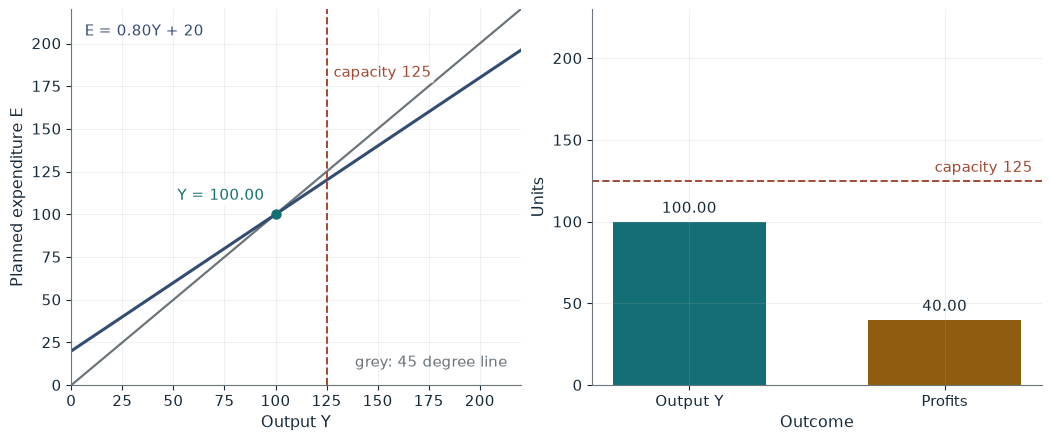

Spending propensity      0.80
Output Y                 100.00
Profits                  40.00
Utilization u            0.800
Profit rate on capacity  0.320

Worked steps:
  1. Propensity = 1 x 0.60 + 0.5 x 0.40 = 0.80
  2. Y = 20 / (1 - 0.80) = 20 / 0.20 = 100.00
  3. Profits = 0.40 x 100.00 = 40.00
  4. Profit rate on capacity = 40.00 / 125 = 0.320

Hypothetical teaching numbers, not data. With wage share 0.60, every unit of output brings 0.80 of consumption, so Y = 20 / 0.20 = 100.00 and profits are 0.40 x 100.00 = 40.00. Utilization is 100.00 / 125 = 0.800 and the profit rate on capacity is 40.00 / 125 = 0.320. In this model profits equal twice autonomous demand whatever the wage share: a wage cut raises the profit share but shrinks output.


In [2]:
show(costs_picture(omega=0.60, auto=20))

Change one input, `omega`, and hold the others at the book's values:

In [3]:
sweep(costs_picture, 'omega', [0.5, 0.6, 0.7], {'auto': 20}, ['Output Y', 'Profits'])

omega | Output Y | Profits
0.5 | 80.00 | 40.00
0.6 | 100.00 | 40.00
0.7 | 133.33 | 40.00


Cutting the wage share from 0.60 to 0.50 lowers output from 100 to 80, but profits stay at 40: in this model profits equal twice autonomous demand.

## 2. Kalecki profit equation: what determines aggregate profits

Hypothetical annual flows in billions.

$$P=C_c+I+(G-T)+(X-M)-S_w, \qquad P=40+120+30-10-20=160$$

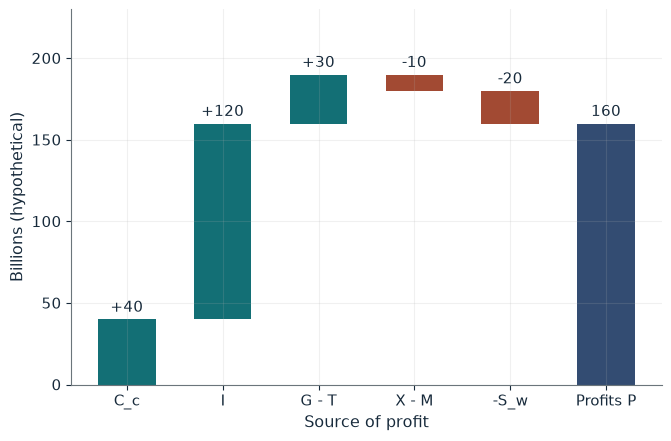

Government deficit      30
Investment              120
Worker saving           20
Profits P               160
Change from book's 160  0

Worked steps:
  1. P = C_c + I + (G - T) + (X - M) - S_w
  2. P = 40 + 120 + 30 - 10 - 20
  3. P = 160

Hypothetical teaching numbers, not data. Profits equal 40 + 120 + 30 - 10 - 20 = 160 billion. Each unit of investment or deficit adds one to profits and each unit of worker saving subtracts one, holding the other entries fixed.


In [4]:
show(profits_picture(deficit=30, inv=120, sw=20))

Change one input, `deficit`, and hold the others at the book's values:

In [5]:
sweep(profits_picture, 'deficit', [10, 30], {'inv': 120, 'sw': 20}, ['Profits P'])

deficit | Profits P
10 | 140
30 | 160


A deficit 20 smaller lowers profits from 160 to 140 unless investment or worker saving changes: 135 of investment and 15 of worker saving restore 160.

## 3. Principle of effective demand: output below capacity

Hypothetical economy with C = 20 + 0.75Y, investment 10 and capacity 160.

$$D^e(N^*)=Z(N^*), \qquad Y=20+0.75Y+10$$

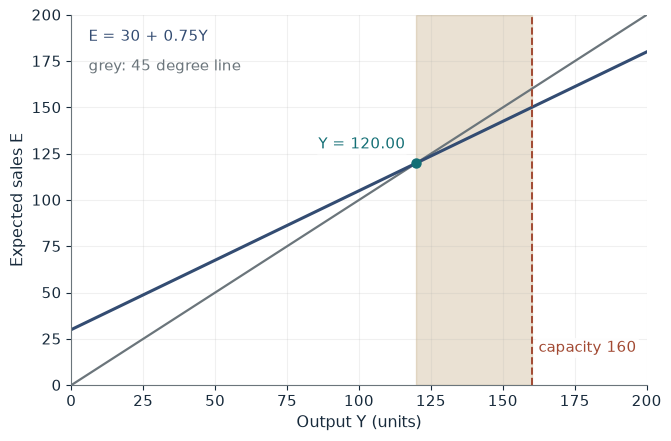

Autonomous spending      30
Multiplier               4.00
Output Y                 120.00
Idle capacity (workers)  40.00

Worked steps:
  1. Y = 20 + 0.75Y + 10 + 0
  2. Y = 30 / (1 - 0.75) = 30 / 0.25 = 120.00
  3. Idle = 160 - 120.00 = 40.00

Hypothetical teaching numbers, not data. Firms produce what they expect to sell: Y = 30 / 0.25 = 120.00, so 40.00 units of capacity and 40.00 workers stay idle. With no public order, output is set by private demand alone.


In [6]:
show(demand_picture(order=0, mpc=0.75))

Change one input, `order`, and hold the others at the book's values:

In [7]:
sweep(demand_picture, 'order', [0, 8, 10], {'mpc': 0.75}, ['Output Y', 'Idle capacity (workers)'])

order | Output Y | Idle capacity (workers)
0 | 120.00 | 40.00
8 | 152.00 | 8.00
10 | 160.00 | 0.00


Output settles at 120 with 40 idle. A credible order of 8 lifts output to 152, and 10 reaches capacity.

## 4. Administered full-cost pricing: markups and demand shocks

Hypothetical producer: overhead 2,000,000, normal volume 100,000, direct cost 60, markup 0.25.

$$c_n=v_n+\frac{K}{Q_n}, \qquad P=(1+m)c_n$$

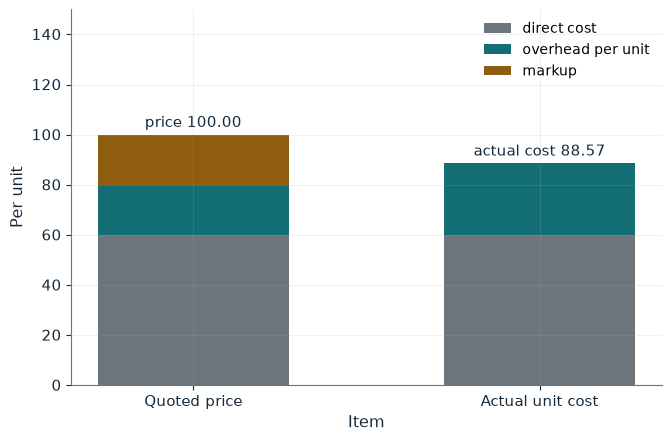

Overhead base          normal volume 100,000
Unit cost for pricing  80.00
Quoted price           100.00
Actual unit cost       88.57
Realized margin        11.43

Worked steps:
  1. Unit cost for pricing = 60 + 2,000,000 / 100,000 = 60 + 20.00 = 80.00
  2. Price = 1.25 x 80.00 = 100.00
  3. Actual cost = 60 + 2,000,000 / 70,000 = 88.57
  4. Margin = 100.00 - 88.57 = 11.43

Hypothetical teaching numbers, not data. Spreading overhead over normal volume 100,000 gives a pricing cost of 80.00 and a quoted price of 1.25 x 80.00 = 100.00. With 70,000 orders the actual unit cost is 88.57, so the realized margin is 11.43 per unit.


In [8]:
show(fullcost_picture(v=60, rule='normal', orders=70000))

Change one input, `v`, and hold the others at the book's values:

In [9]:
sweep(fullcost_picture, 'v', [60, 68], {'rule': 'normal', 'orders': 70000}, ['Quoted price', 'Realized margin'])

v | Quoted price | Realized margin
60 | 100.00 | 11.43
68 | 110.00 | 13.43


Orders of 70,000 leave the price at 100 while the margin falls to 11.43. A direct cost of 68 raises the price to 110; pricing on current volume would give 120.71.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

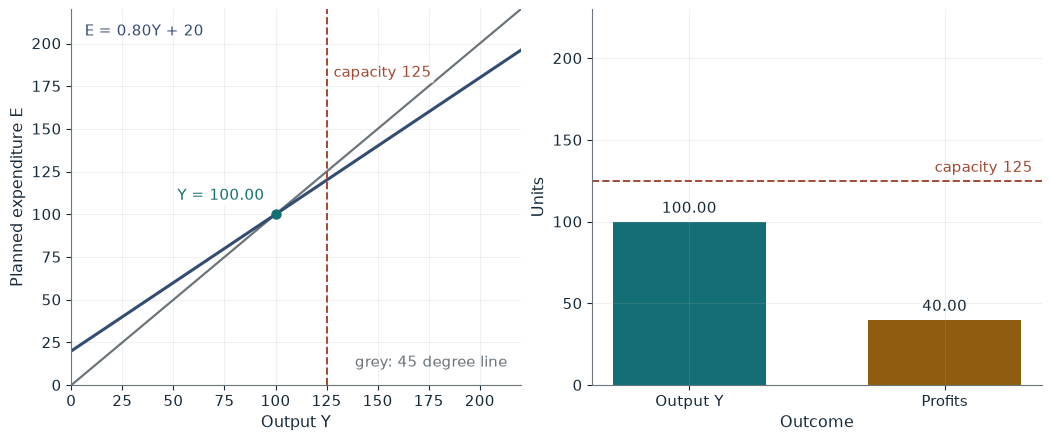

Spending propensity      0.80
Output Y                 100.00
Profits                  40.00
Utilization u            0.800
Profit rate on capacity  0.320

Worked steps:
  1. Propensity = 1 x 0.60 + 0.5 x 0.40 = 0.80
  2. Y = 20 / (1 - 0.80) = 20 / 0.20 = 100.00
  3. Profits = 0.40 x 100.00 = 40.00
  4. Profit rate on capacity = 40.00 / 125 = 0.320

Hypothetical teaching numbers, not data. With wage share 0.60, every unit of output brings 0.80 of consumption, so Y = 20 / 0.20 = 100.00 and profits are 0.40 x 100.00 = 40.00. Utilization is 100.00 / 125 = 0.800 and the profit rate on capacity is 40.00 / 125 = 0.320. In this model profits equal twice autonomous demand whatever the wage share: a wage cut raises the profit share but shrinks output.


In [10]:
show(costs_picture(omega=0.60, auto=20))

## Practice

**1.** With wage share 0.70 and autonomous demand 16, what are output and profits?

<details><summary>Answer</summary>

Propensity 0.85, so Y = 16 / 0.15 = 106.67 and profits 0.30 x 106.67 = 32.

</details>

**2.** With deficit 10, investment 120 and worker saving 15, what are profits?

<details><summary>Answer</summary>

40 + 120 + 10 - 10 - 15 = 145.

</details>

**3.** With mpc 0.70 and an 8 unit order, what is output?

<details><summary>Answer</summary>

Y = (20 + 10 + 8) / 0.30 = 126.67.

</details>